# Analyse Exploratoire des Données (EDA)

## Imports et Configuration

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# Style des graphiques
sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Chemin du dataset brut depuis le dossier notebooks/
DATA_PATH = os.path.join("..", "data", "raw", "uav_trajectories_raw.csv")

print(f"Chargement des données depuis : {DATA_PATH}")
df = pd.read_csv(DATA_PATH)

Chargement des données depuis : ../data/raw/uav_trajectories_raw.csv


## Structure

In [2]:
# 1. Aperçu général et détection automatique des colonnes
print(f"Dimensions du jeu de données : {df.shape[0]:,} lignes, {df.shape[1]} colonnes\n")

# Normalisation des noms de colonnes (gestion casse min/maj)
df.columns = [c.strip() for c in df.columns]
col_map = {c: c.lower() for c in df.columns}
df = df.rename(columns=col_map)

print("Information sur les types de données :")
print(df.info())

print("\nVérification des valeurs manquantes :")
print(df.isnull().sum())

Dimensions du jeu de données : 43,573 lignes, 5 colonnes

Information sur les types de données :
<class 'pandas.DataFrame'>
RangeIndex: 43573 entries, 0 to 43572
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  43573 non-null  float64
 1   tx         43573 non-null  float64
 2   ty         43573 non-null  float64
 3   tz         43573 non-null  float64
 4   drone_id   43573 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 1.7 MB
None

Vérification des valeurs manquantes :
timestamp    0
tx           0
ty           0
tz           0
drone_id     0
dtype: int64


## Statistiques Spatiales ($X, Y, Z$) et Temporelles

In [3]:
# Identifier les colonnes cartésiennes
x_col = [c for c in df.columns if 'x' in c][0]
y_col = [c for c in df.columns if 'y' in c][0]
z_col = [c for c in df.columns if 'z' in c][0]
id_col = [c for c in df.columns if 'drone' in c or 'id' in c][0]
time_col = [c for c in df.columns if 'time' in c or 'stamp' in c][0]

print("--- BORNES DE LA GRILLE SPATIALE 3D ---")
print(f"Axe X : Min = {df[x_col].min():.2f} m | Max = {df[x_col].max():.2f} m | Étendue = {df[x_col].max() - df[x_col].min():.2f} m")
print(f"Axe Y : Min = {df[y_col].min():.2f} m | Max = {df[y_col].max():.2f} m | Étendue = {df[y_col].max() - df[y_col].min():.2f} m")
print(f"Axe Z : Min = {df[z_col].min():.2f} m | Max = {df[z_col].max():.2f} m | Étendue = {df[z_col].max() - df[z_col].min():.2f} m")

print("\n--- STATISTIQUES DE LA FLOTTE ---")
n_drones = df[id_col].nunique()
pts_per_drone = df.groupby(id_col).size()
print(f"Nombre de drones uniques : {n_drones}")
print(f"Points par drone : Min = {pts_per_drone.min()} | Max = {pts_per_drone.max()} | Moyenne = {pts_per_drone.mean():.1f}")

--- BORNES DE LA GRILLE SPATIALE 3D ---
Axe X : Min = -43.83 m | Max = 44.56 m | Étendue = 88.39 m
Axe Y : Min = -44.31 m | Max = 42.91 m | Étendue = 87.21 m
Axe Z : Min = 4.91 m | Max = 20.08 m | Étendue = 15.18 m

--- STATISTIQUES DE LA FLOTTE ---
Nombre de drones uniques : 250
Points par drone : Min = 100 | Max = 251 | Moyenne = 174.3


## Visualisation 1 - Trajectoires 3D de la Flotte

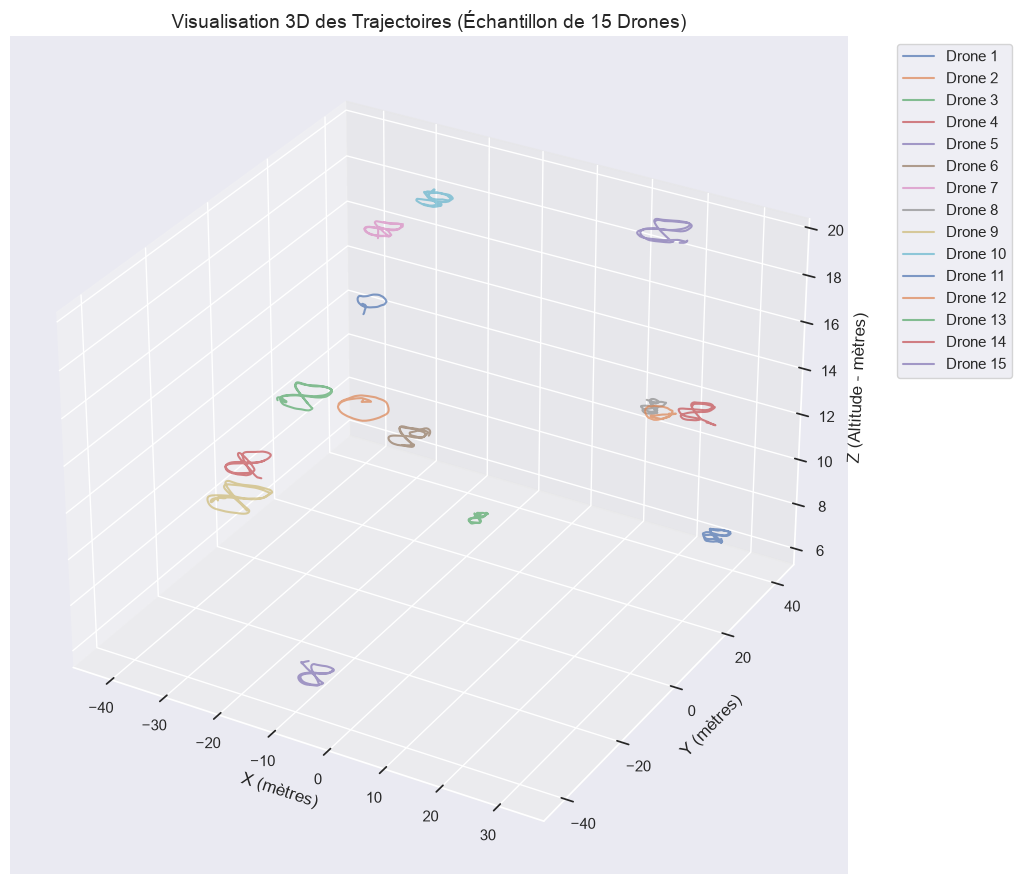

In [4]:
# Sélection d'un échantillon de drones pour la lisibilité
sample_drones = df[id_col].unique()[:15]
df_sample = df[df[id_col].isin(sample_drones)]

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

for d_id, group in df_sample.groupby(id_col):
    ax.plot(group[x_col], group[y_col], group[z_col], label=f'Drone {d_id}', alpha=0.7)

ax.set_title(f"Visualisation 3D des Trajectoires (Échantillon de 15 Drones)", fontsize=14)
ax.set_xlabel("X (mètres)")
ax.set_ylabel("Y (mètres)")
ax.set_zlabel("Z (Altitude - mètres)")
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Visualisation 2 - Profil d'Altitude (Z) et Distribution Temporelle

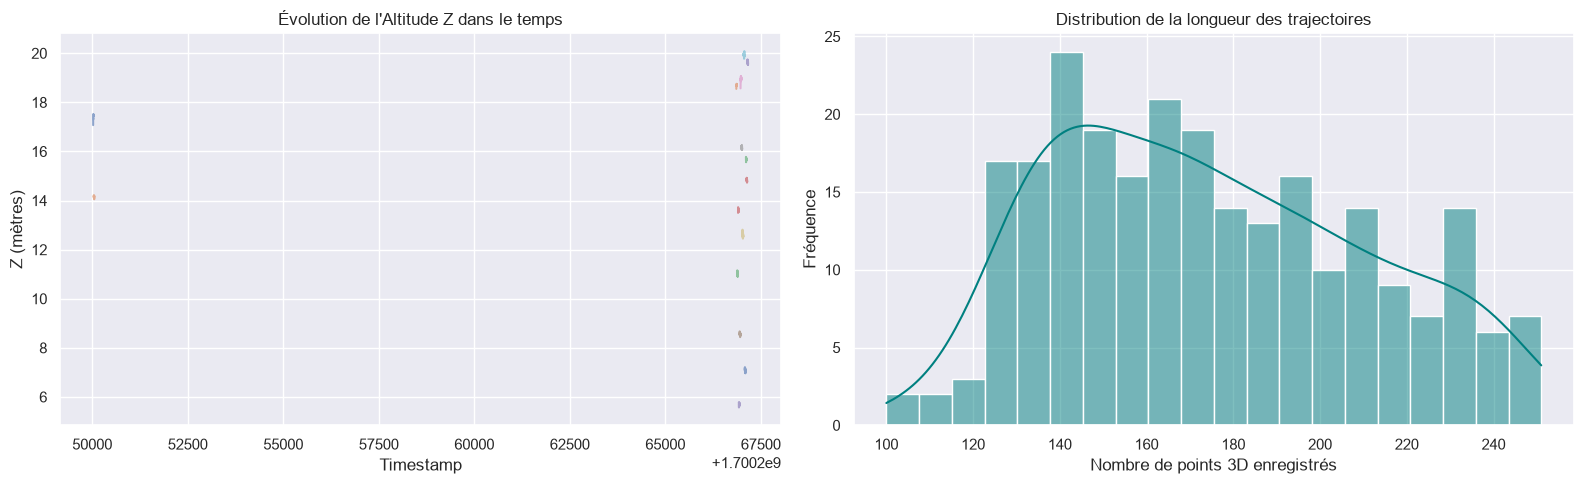

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Graphique A : Profil d'altitude
for d_id, group in df_sample.groupby(id_col):
    axes[0].plot(group[time_col], group[z_col], alpha=0.6)
axes[0].set_title("Évolution de l'Altitude Z dans le temps")
axes[0].set_xlabel("Timestamp")
axes[0].set_ylabel("Z (mètres)")

# Graphique B : Distribution du nombre de points par drone
sns.histplot(pts_per_drone, kde=True, ax=axes[1], color="teal", bins=20)
axes[1].set_title("Distribution de la longueur des trajectoires")
axes[1].set_xlabel("Nombre de points 3D enregistrés")
axes[1].set_ylabel("Fréquence")

plt.tight_layout()
plt.show()

## Analyse Dynamique (Vitesse instantanée & Détection des anomalies)

--- ANALYSE DE LA VITESSE CINÉMATIQUE (Préparation Agent 2 - Cybersécurité) ---
Déplacement moyen par pas : 0.255 m
Déplacement max par pas   : 0.737 m
Écart-type (Std Dev)       : 0.127 m


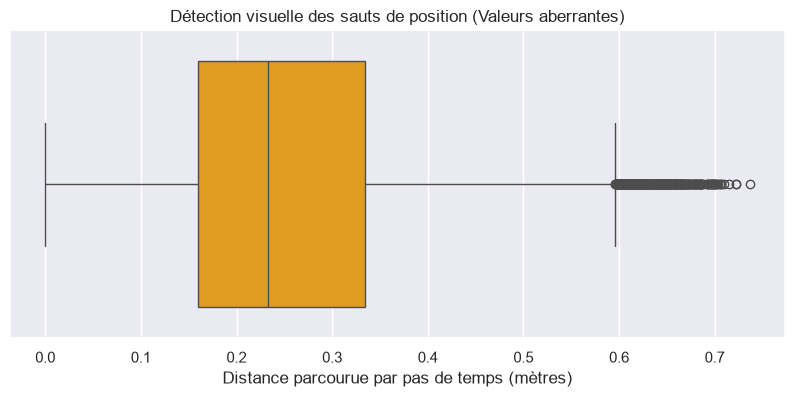

In [6]:
# Calcul des déplacements delta entre chaque frame
df['dx'] = df.groupby(id_col)[x_col].diff().fillna(0)
df['dy'] = df.groupby(id_col)[y_col].diff().fillna(0)
df['dz'] = df.groupby(id_col)[z_col].diff().fillna(0)

# Distance euclidienne parcourue par pas de temps
df['step_distance'] = np.sqrt(df['dx']**2 + df['dy']**2 + df['dz']**2)

print("--- ANALYSE DE LA VITESSE CINÉMATIQUE (Préparation Agent 2 - Cybersécurité) ---")
print(f"Déplacement moyen par pas : {df['step_distance'].mean():.3f} m")
print(f"Déplacement max par pas   : {df['step_distance'].max():.3f} m")
print(f"Écart-type (Std Dev)       : {df['step_distance'].std():.3f} m")

# Visualisation des sauts physiques
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['step_distance'], color="orange")
plt.title("Détection visuelle des sauts de position (Valeurs aberrantes)")
plt.xlabel("Distance parcourue par pas de temps (mètres)")
plt.show()

# Plan de Prétraitement et Pipeline de Données (Phase Offline)

À partir des résultats valides de l'EDA (43 573 points 3D, 250 drones, déplacement max nominal = 0,737 m, altitude Z ∈ [4,91 m, 20,08 m]), voici la feuille de route du prétraitement pour la transition vers l'architecture multi-agents.

---

### 1. Synchronisation Temporelle et Alignement de la Flotte (`frame_id`)
* **Problématique** : Chaque fichier de vol possède sa propre échelle temporelle `timestamp`. Pour simuler une vraie flotte évoluant en temps réel, tous les drones doivent être synchronisés sur une horloge commune.
* **Actions** :
  1. Recaler l'horodatage initial $t_0 = 0$ pour chaque drone.
  2. Créer une variable entière `frame_id` (pas de temps universel à 30 Hz).
  3. Aligner les 250 drones sur cet axe `frame_id` afin que la boucle d'exécution mette à jour l'ensemble de la flotte pas à pas.

---

### 2. Discrétisation et Indexation dans la Grille Spatiale 3D
* **Dimensions globales mesurées** :
  * $X \in [-45, +45]$ m (Étendue ≈ 90 m)
  * $Y \in [-45, +45]$ m (Étendue ≈ 90 m)
  * $Z \in [0, 25]$ m (Étendue ≈ 25 m)
* **Configuration des Voxels** :
  * Taille d'une cellule 3D : **$10\text{ m} \times 10\text{ m} \times 5\text{ m}$** (soit une grille de $9 \times 9 \times 5 = 405$ cellules uniques).
* **Formule de Hashing / Indexation Spatiale** :
  $$cell\_x = \lfloor \frac{tx - X_{min}}{10} \rfloor, \quad cell\_y = \lfloor \frac{ty - Y_{min}}{10} \rfloor, \quad cell\_z = \lfloor \frac{tz - Z_{min}}{5} \rfloor$$
  $$cell\_id = cell\_x + (cell\_y \times N_x) + (cell\_z \times N_x \times N_y)$$
* **Usage** : Permet à la Grille 3D de retrouver les drones voisins en complexité constante $\mathcal{O}(1)$ au lieu de $\mathcal{O}(N^2)$.

---

### 3. Ingénierie des Caractéristiques Cinématiques (Feature Engineering)
Création des variables physiques dérivées à partir des coordonnées $(tx, ty, tz)$ et du $\Delta t$ :
* **Composantes de Vitesse ($m/s$)** : $V_x = \frac{\Delta tx}{\Delta t}$, $V_y = \frac{\Delta ty}{\Delta t}$, $V_z = \frac{\Delta tz}{\Delta t}$
* **Norme de Vitesse Globale ($m/s$)** : $\|\mathbf{V}\| = \sqrt{V_x^2 + V_y^2 + V_z^2}$
* **Composantes d'Accélération ($m/s^2$)** : $A_x = \frac{\Delta V_x}{\Delta t}$, $A_y = \frac{\Delta V_y}{\Delta t}$, $A_z = \frac{\Delta V_z}{\Delta t}$
* **Seuil de Rupture Physique (Agent 2)** : Seuil fixe calculé à $\text{Distance\_Max} + 3\sigma = 0,737 + (3 \times 0,127) \approx 1,11\text{ m}$. Tout saut supérieur à ce seuil entre 2 pas successifs sera considéré comme une rupture cinématique.

---

### 4. Injection Synthétique de Pannes et Attaques (Labels de Test)
Pour évaluer les agents IA de manière déterministe, deux scripts de perturbation seront appliqués sur une copie de validation :
1. **Agent 2 (Cybersecurity / Anti-Spoofing)** :
   * Injection d'erreurs de positionnement (sauts d'offset artificiels de $+5\text{ m}$ à $+15\text{ m}$ sur $tx, ty$) sur 5 % des frames choisies aléatoirement.
   * Création de la colonne cible : `is_spoofed` ($0$ = nominal, $1$ = sous attaque).
2. **Agent 3 (Prediction / Blackout)** :
   * Masquage de séquences consécutives (périodes de blackout de 15 à 30 frames, soit 0.5s à 1s de coupure réseau).
   * Création de la colonne cible : `is_blackout` ($0$ = connecté, $1$ = signal perdu).

---

### 5. Préparation des Séquences Glissantes pour l'Agent 3 (LSTM)
* **Fenêtrage temporel (Sliding Window)** :
  * **Entrée (Input)** : 10 pas de temps passés $[t-9, \dots, t]$ ($\mathbf{X} \in \mathbb{R}^{10 \times 3}$ pour $tx, ty, tz$).
  * **Cible (Output)** : 5 pas de temps futurs à prédire $[t+1, \dots, t+5]$ ($\mathbf{Y} \in \mathbb{R}^{5 \times 3}$).
* **Normalisation (MinMax Scaler)** : Redimensionner les coordonnées spatiales dans l'intervalle $[0, 1]$ par drone pour stabiliser la convergence du modèle récurrent.

---

### 6. Format Final du CSV Prétraité (`fleet_telemetry_processed.csv`)
Le script de prétraitement exportera un fichier unifié contenant les colonnes suivantes :
`[frame_id, timestamp, drone_id, tx, ty, tz, vx, vy, vz, step_dist, cell_id, is_spoofed, is_blackout]`